# LAB3 - Bài 2 (Trang 5): Neural Network trên MNIST (chia train - validation - test)
**Đinh Nhật Huyền Nhân - 6451071055 - CQ.64.CNTT**

In [1]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# a) Đọc bộ dữ liệu train, test của MNIST từ Keras
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
from tensorflow.keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("Đã đọc MNIST.")

Đinh Nhật Huyền Nhân - 6451071055


Đã đọc MNIST.


In [2]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# b) Kích thước tập train, test
print("train_images:", train_images.shape, "| train_labels:", train_labels.shape)
print("test_images :", test_images.shape, "| test_labels :", test_labels.shape)

Đinh Nhật Huyền Nhân - 6451071055
train_images: (60000, 28, 28) | train_labels: (60000,)
test_images : (10000, 28, 28) | test_labels : (10000,)


In [3]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# c) Chuẩn hóa pixel về [0,1]
train_images = train_images / 255.0
test_images = test_images / 255.0
print("Min/Max train:", train_images.min(), train_images.max())
print("Min/Max test :", test_images.min(), test_images.max())

Đinh Nhật Huyền Nhân - 6451071055
Min/Max train: 0.0 1.0
Min/Max test : 0.0 1.0


In [4]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# d) Chia tập train ban đầu thành train và validation theo tỷ lệ 8:2
from sklearn.model_selection import train_test_split
train_images, validation_images, train_labels, validation_labels = train_test_split(
    train_images, train_labels, test_size=0.2, random_state=42)
print("train_images     :", train_images.shape, "| train_labels     :", train_labels.shape)
print("validation_images:", validation_images.shape, "| validation_labels:", validation_labels.shape)

Đinh Nhật Huyền Nhân - 6451071055
train_images     : (48000, 28, 28) | train_labels     : (48000,)
validation_images: (12000, 28, 28) | validation_labels: (12000,)


In [5]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# e) Xây dựng Neural Network: Flatten -> Dense(128, relu) -> Dropout(0.2) -> Dense(10, softmax)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout, Input
tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),                         # 28x28 -> vector 784 chiều
    Dense(128, activation="relu"),
    Dropout(0.2),                      # tắt ngẫu nhiên 20% neuron khi huấn luyện
    Dense(10, activation="softmax"),
])
model.summary()

Đinh Nhật Huyền Nhân - 6451071055


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# f) Biên dịch mô hình
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("Đã biên dịch: optimizer=adam, loss=sparse_categorical_crossentropy, metrics=accuracy")

Đinh Nhật Huyền Nhân - 6451071055
Đã biên dịch: optimizer=adam, loss=sparse_categorical_crossentropy, metrics=accuracy


In [7]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# g) Huấn luyện trên tập train, đánh giá với tập validation; epochs=5, batch_size=32
history = model.fit(train_images, train_labels, epochs=5, batch_size=32,
                    validation_data=(validation_images, validation_labels), verbose=2)

Đinh Nhật Huyền Nhân - 6451071055
Epoch 1/5


1500/1500 - 3s - 2ms/step - accuracy: 0.9050 - loss: 0.3287 - val_accuracy: 0.9537 - val_loss: 0.1658


Epoch 2/5


1500/1500 - 3s - 2ms/step - accuracy: 0.9531 - loss: 0.1612 - val_accuracy: 0.9638 - val_loss: 0.1221


Epoch 3/5


1500/1500 - 3s - 2ms/step - accuracy: 0.9647 - loss: 0.1204 - val_accuracy: 0.9704 - val_loss: 0.1033


Epoch 4/5


1500/1500 - 3s - 2ms/step - accuracy: 0.9706 - loss: 0.0969 - val_accuracy: 0.9733 - val_loss: 0.0923


Epoch 5/5


1500/1500 - 3s - 2ms/step - accuracy: 0.9745 - loss: 0.0817 - val_accuracy: 0.9732 - val_loss: 0.0899


Đinh Nhật Huyền Nhân - 6451071055


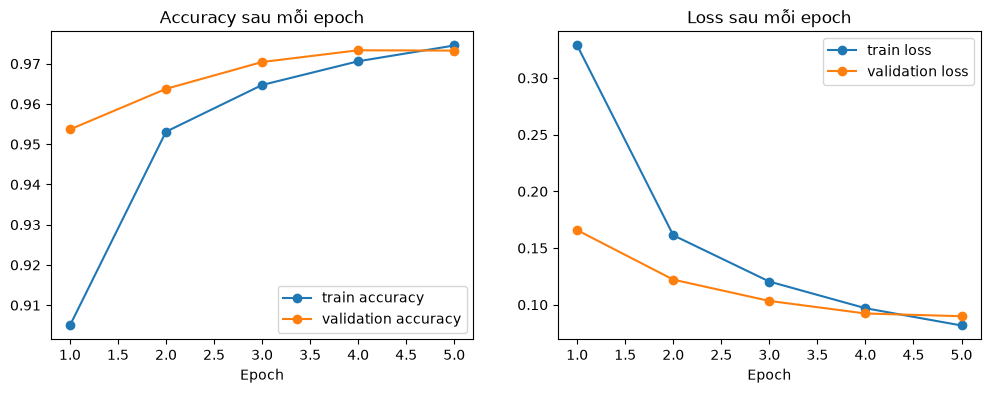

In [8]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# h) Biểu đồ accuracy, loss sau mỗi epoch
ep = range(1, len(history.history["loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, history.history["accuracy"], "o-", label="train accuracy")
ax[0].plot(ep, history.history["val_accuracy"], "o-", label="validation accuracy")
ax[0].set_title("Accuracy sau mỗi epoch"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(ep, history.history["loss"], "o-", label="train loss")
ax[1].plot(ep, history.history["val_loss"], "o-", label="validation loss")
ax[1].set_title("Loss sau mỗi epoch"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.show()

In [9]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# i) Dự đoán phân lớp cho tập test
y_prob = model.predict(test_images, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
print("10 nhãn dự đoán đầu tiên:", y_pred[:10])
print("10 nhãn thực tế đầu tiên:", test_labels[:10])

Đinh Nhật Huyền Nhân - 6451071055


10 nhãn dự đoán đầu tiên: [7 2 1 0 4 1 4 9 5 9]
10 nhãn thực tế đầu tiên: [7 2 1 0 4 1 4 9 5 9]


In [10]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# j) Accuracy trên tập test
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
print("Accuracy trên tập test:", accuracy_score(test_labels, y_pred))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy trên tập test: 0.9745


In [11]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# k) Precision, Recall, F1-score của từng lớp và trung bình
print(classification_report(test_labels, y_pred, digits=4))

Đinh Nhật Huyền Nhân - 6451071055
              precision    recall  f1-score   support

           0     0.9877    0.9867    0.9872       980
           1     0.9850    0.9868    0.9859      1135
           2     0.9610    0.9777    0.9693      1032
           3     0.9620    0.9762    0.9690      1010
           4     0.9688    0.9796    0.9742       982
           5     0.9741    0.9709    0.9725       892
           6     0.9761    0.9802    0.9781       958
           7     0.9765    0.9708    0.9737      1028
           8     0.9719    0.9579    0.9648       974
           9     0.9817    0.9564    0.9689      1009

    accuracy                         0.9745     10000
   macro avg     0.9745    0.9743    0.9744     10000
weighted avg     0.9746    0.9745    0.9745     10000



Đinh Nhật Huyền Nhân - 6451071055


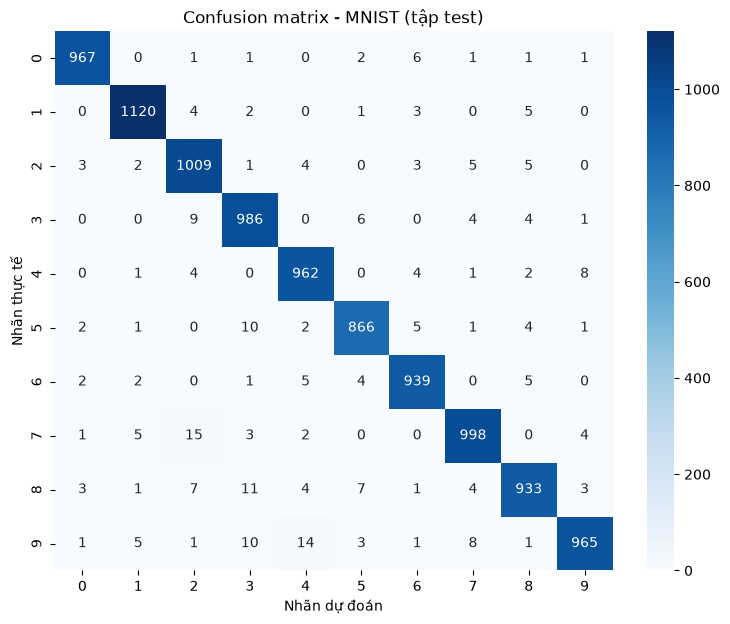

In [12]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# l) Confusion matrix bằng heat map
cm = confusion_matrix(test_labels, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Nhãn dự đoán"); plt.ylabel("Nhãn thực tế"); plt.title("Confusion matrix - MNIST (tập test)")
plt.show()

Đinh Nhật Huyền Nhân - 6451071055
Ảnh 0: dự đoán = 7, thực tế = 7
Ảnh 1: dự đoán = 2, thực tế = 2
Ảnh 2: dự đoán = 1, thực tế = 1


Ảnh 3: dự đoán = 0, thực tế = 0
Ảnh 4: dự đoán = 4, thực tế = 4


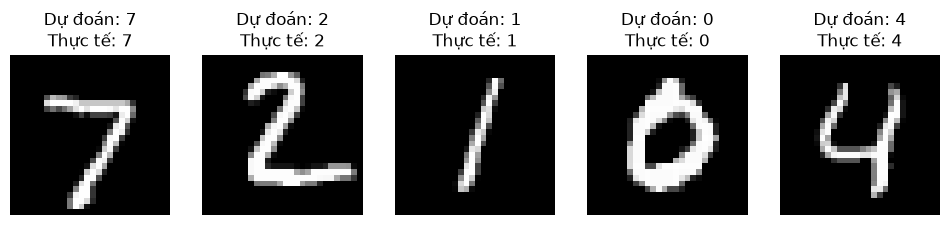

In [13]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# m) Kết quả phân lớp của 05 ảnh đầu tiên trong tập test
plt.figure(figsize=(12, 3))
for idx in range(5):
    img = np.expand_dims(test_images[idx], axis=0)          # (1, 28, 28)
    du_doan = np.argmax(model.predict(img, verbose=0), axis=1)[0]
    print(f"Ảnh {idx}: dự đoán = {du_doan}, thực tế = {test_labels[idx]}")
    plt.subplot(1, 5, idx + 1)
    plt.imshow(test_images[idx], cmap="gray")
    plt.title(f"Dự đoán: {du_doan}\nThực tế: {test_labels[idx]}")
    plt.axis("off")
plt.show()

Đinh Nhật Huyền Nhân - 6451071055
Tổng số ảnh phân lớp sai: 255
Ảnh index 151: dự đoán = 8, thực tế = 9
Ảnh index 247: dự đoán = 2, thực tế = 4
Ảnh index 321: dự đoán = 7, thực tế = 2
Ảnh index 340: dự đoán = 3, thực tế = 5
Ảnh index 359: dự đoán = 4, thực tế = 9


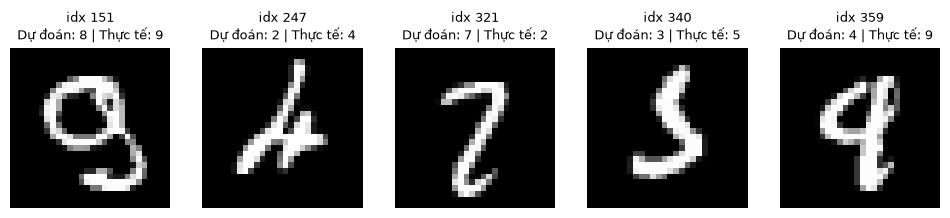

In [14]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# n) 05 kết quả đầu tiên phân lớp sai so với nhãn thực tế
sai = np.where(y_pred != test_labels)[0]
print("Tổng số ảnh phân lớp sai:", len(sai))
plt.figure(figsize=(12, 3))
for k, idx in enumerate(sai[:5]):
    print(f"Ảnh index {idx}: dự đoán = {y_pred[idx]}, thực tế = {test_labels[idx]}")
    plt.subplot(1, 5, k + 1)
    plt.imshow(test_images[idx], cmap="gray")
    plt.title(f"idx {idx}\nDự đoán: {y_pred[idx]} | Thực tế: {test_labels[idx]}", fontsize=9)
    plt.axis("off")
plt.show()